In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)  # для воспроизводимости

In [2]:
train = pd.read_csv('train.csv', header=None).values          # 1000 x 5000
test = pd.read_csv('test.csv', header=None).values            # 500 x 5000
etalon_train = pd.read_csv('etalon_for_train.csv', header=None).values
etalon_test = pd.read_csv('etalon_for_test.csv', header=None).values

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Etalon test shape:", etalon_test.shape)

Train shape: (1000, 5000)
Test shape: (500, 5000)
Etalon test shape: (500, 5000)


In [3]:
dt = 0.05
N = 4000          # длина истории
H = 1000          # длина прогноза (50 с / 0.05 с)
L = 500           # число тестовых реализаций

# Разделение на историю и цель для каждой реализации
X_train = train[:, :N]              # 1000 x 4000
Y_train = etalon_train[:, N:]       # 1000 x 1000 (что хотим предсказать)

X_test = test[:, :N]                # 500 x 4000
Y_test = etalon_test[:, N:]         # 500 x 1000

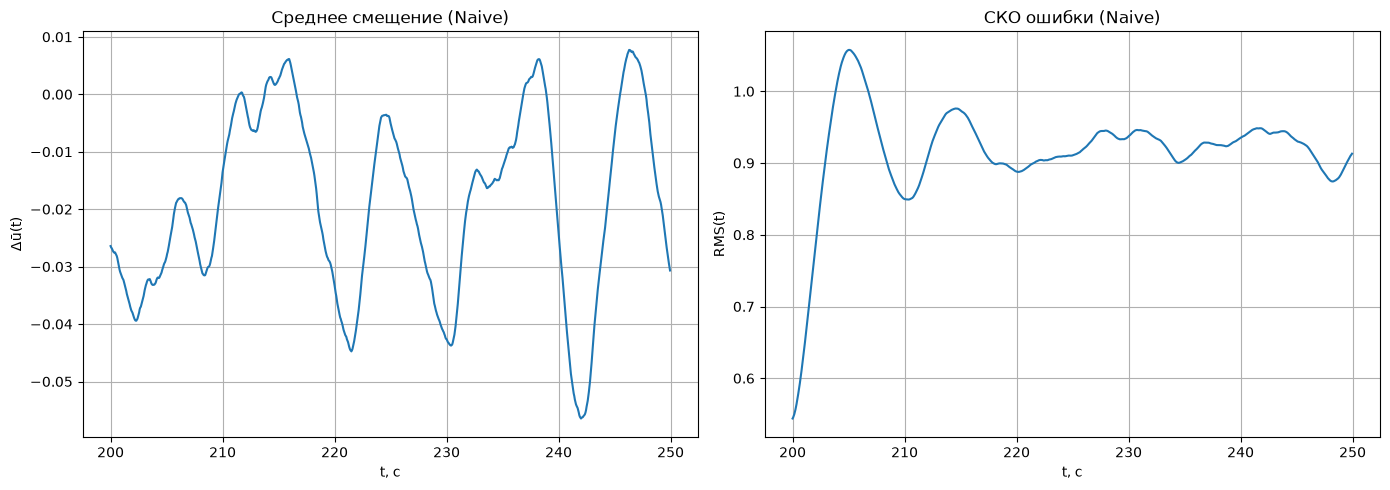

In [4]:
# Сначала сделаю простой прогноз Baseline 1: прогноз = последнее значение из истории
Y_pred_naive = np.tile(X_test[:, -1:], (1, H))

# Оценка
def evaluate(Y_pred, Y_true):
    """Считает Δu(t) и RMS(t) по формулам (2) и (3)."""
    diff = Y_pred - Y_true                    
    mean_diff = diff.mean(axis=0)              
    centered = diff - mean_diff                # центрированная ошибка
    rms = np.sqrt((centered**2).sum(axis=0) / (L - 1))  # RMS(t)
    return mean_diff, rms

mean_naive, rms_naive = evaluate(Y_pred_naive, Y_test)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t_axis = np.arange(N, N + H) * dt
axes[0].plot(t_axis, mean_naive)
axes[0].set_title('Среднее смещение (Naive)')
axes[0].set_xlabel('t, с'); axes[0].set_ylabel('Δū(t)'); axes[0].grid()
axes[1].plot(t_axis, rms_naive)
axes[1].set_title('СКО ошибки (Naive)')
axes[1].set_xlabel('t, с'); axes[1].set_ylabel('RMS(t)'); axes[1].grid()
plt.tight_layout(); plt.show()

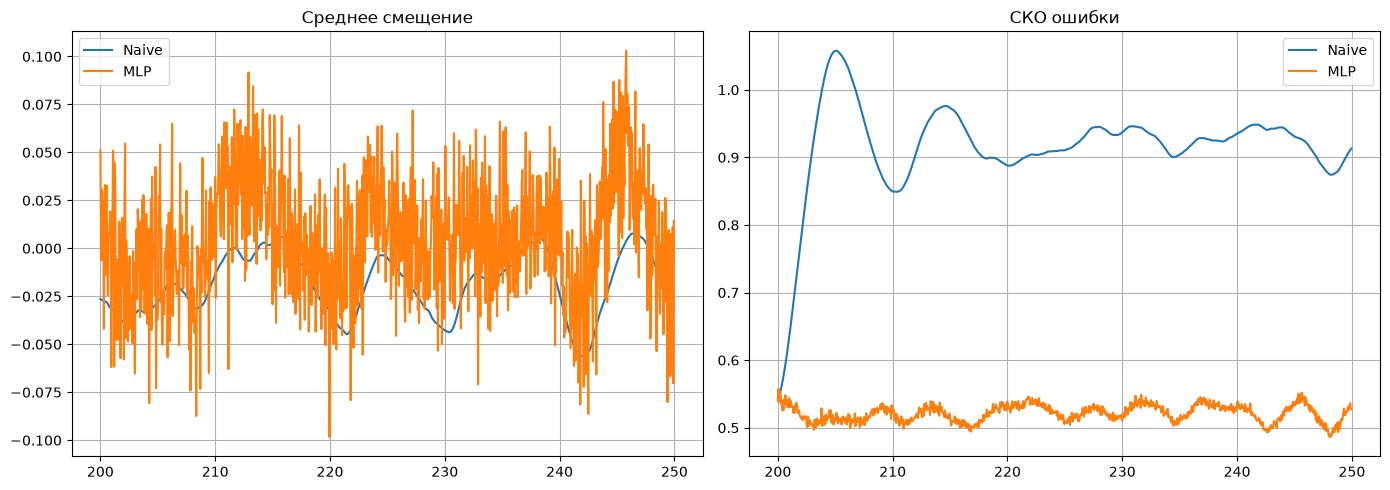

Naive: mean|Δu| = 0.0201, mean RMS = 0.9150
MLP:   mean|Δu| = 0.0257, mean RMS = 0.5215


In [6]:
# Обучение
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True)

mlp.fit(X_train_sc, Y_train)
Y_pred_mlp = mlp.predict(X_test_sc)

# Оценка
mean_mlp, rms_mlp = evaluate(Y_pred_mlp, Y_test)

# Сравнение на графике
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(t_axis, mean_naive, label='Naive')
axes[0].plot(t_axis, mean_mlp, label='MLP')
axes[0].set_title('Среднее смещение'); axes[0].legend(); axes[0].grid()
axes[1].plot(t_axis, rms_naive, label='Naive')
axes[1].plot(t_axis, rms_mlp, label='MLP')
axes[1].set_title('СКО ошибки'); axes[1].legend(); axes[1].grid()
plt.tight_layout(); plt.show()

print(f"Naive: mean|Δu| = {np.mean(np.abs(mean_naive)):.4f}, "
      f"mean RMS = {np.mean(rms_naive):.4f}")
print(f"MLP:   mean|Δu| = {np.mean(np.abs(mean_mlp)):.4f}, "
      f"mean RMS = {np.mean(rms_mlp):.4f}")

   Model  mean |Δu|  mean RMS
0  Naive   0.020107  0.915019
1    MLP   0.025651  0.521463


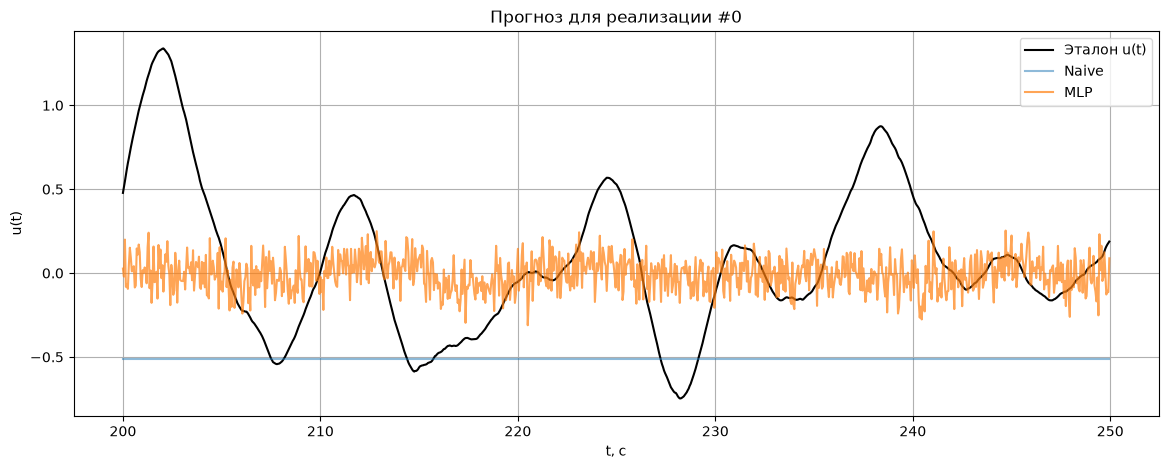

In [12]:
# Сводная таблица
results = pd.DataFrame({
    'Model': ['Naive', 'MLP'],
    'mean |Δu|': [np.mean(np.abs(mean_naive)), np.mean(np.abs(mean_mlp))],
    'mean RMS': [np.mean(rms_naive), np.mean(rms_mlp)]})
print(results)

# Визуализация примера прогноза одной реализации
k = 0  # номер реализации
plt.figure(figsize=(14, 5))
plt.plot(t_axis, Y_test[k], label='Эталон u(t)', color='black')
plt.plot(t_axis, Y_pred_naive[k], label='Naive', alpha=0.5)
plt.plot(t_axis, Y_pred_mlp[k], label='MLP', alpha=0.7)
plt.xlabel('t, с'); plt.ylabel('u(t)'); plt.legend(); plt.grid()
plt.title(f'Прогноз для реализации #{k}')
plt.show()